In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay



In [3]:
# Step 1: Load dataset
data = pd.read_csv("spam.csv", encoding="latin-1", usecols=["v1", "v2"])
data.columns = ["label", "message"]

print(data.head())


  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [4]:

# Step 2: Clean the dataset
data = data.dropna()
data["message"] = data["message"].str.lower().str.strip()
data = data[data["message"] != ""].copy()
data["label"] = data["label"].map({"ham": 0, "spam": 1})



In [5]:
# Step 3: Separate features and target
X = data["message"]
y = data["label"]

# Step 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



In [6]:
# Step 5: Convert text into numbers
vectorizer = CountVectorizer()

X_train_numbers = vectorizer.fit_transform(X_train)
X_test_numbers = vectorizer.transform(X_test)

# Step 6: Train Naive Bayes model
model = MultinomialNB()
model.fit(X_train_numbers, y_train)



MultinomialNB()

In [7]:
# Step 7: Make predictions
predictions = model.predict(X_test_numbers)

# Step 8: Evaluate model
print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1 Score:", f1_score(y_test, predictions))



Accuracy: 0.9838565022421525
Precision: 0.9645390070921985
Recall: 0.912751677852349
F1 Score: 0.9379310344827586


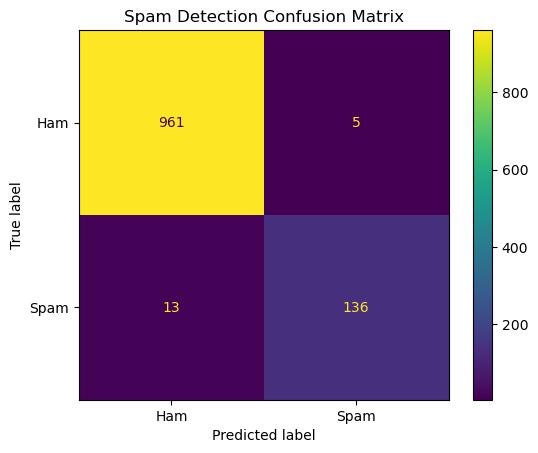

In [9]:
# Step 9: Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions,
    labels=[0, 1],
    display_labels=["Ham", "Spam"]
)

plt.title("Spam Detection Confusion Matrix")
plt.show()


In [10]:

# Step 10: Predict a new message
new_message = ["Congratulations! You won a free prize!"]

new_numbers = vectorizer.transform(new_message)
answer = model.predict(new_numbers)[0]

if answer == 1:
    print("Spam Message")
else:
    print("Ham Message")


Spam Message
